<h2>import des bibliothèques</h2>

In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt


import random

from PIL import Image
from glob import glob
from collections import Counter


from scipy import ndimage




In [2]:
import re, random
from collections import defaultdict
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

MANIFEST = "split_manifest.json"

<h2>Vérification de l'existence et de la structure du dataset RoadAnomaly</h2>

In [3]:

import os

dataset_path = r"<user home>\Downloads\RoadAnomaly\RoadAnomaly"
frames_path = os.path.join(dataset_path, "frames")
print("Dossier du dataset :", os.path.exists(dataset_path))
print("Dossier des images :", os.path.exists(frames_path))
MANIFEST = "split_manifest.json"
if os.path.exists(frames_path):
    print("Premiers fichiers :")
    print(os.listdir(frames_path)[:10])

Dossier du dataset : True
Dossier des images : True
Premiers fichiers :
['animals01_Guiguinto_railway_station_Calves.labels', 'animals01_Guiguinto_railway_station_Calves.webp', 'animals02_Zagori_On_the_road_to_Papigko.labels', 'animals02_Zagori_On_the_road_to_Papigko.webp', 'animals03_Zebras_in_the_road.labels', 'animals03_Zebras_in_the_road.webp', 'animals04_17_animal_casualties_so_far_in_2006.labels', 'animals04_17_animal_casualties_so_far_in_2006.webp', 'animals05_cows_near_Phonsavan_Laos.labels', 'animals05_cows_near_Phonsavan_Laos.webp']


<h2>nom des premiers éléments</h2>

In [4]:
files = os.listdir(frames_path)

print("Nombre total de fichiers et dossiers :", len(files))
print("\nPremiers éléments :")

for file in files[:15]:
    print(file)

Nombre total de fichiers et dossiers : 120

Premiers éléments :
animals01_Guiguinto_railway_station_Calves.labels
animals01_Guiguinto_railway_station_Calves.webp
animals02_Zagori_On_the_road_to_Papigko.labels
animals02_Zagori_On_the_road_to_Papigko.webp
animals03_Zebras_in_the_road.labels
animals03_Zebras_in_the_road.webp
animals04_17_animal_casualties_so_far_in_2006.labels
animals04_17_animal_casualties_so_far_in_2006.webp
animals05_cows_near_Phonsavan_Laos.labels
animals05_cows_near_Phonsavan_Laos.webp
animals06_sheep_roads_lambs.labels
animals06_sheep_roads_lambs.webp
animals07_Aihole_Pattadakal.labels
animals07_Aihole_Pattadakal.webp
animals08_on_the_main_street_of_village_Lin_Albania.labels


<h2>Nombre d'images et de masques</h2>

In [5]:


images = sorted(glob(os.path.join(frames_path, "*.webp")))

masks = sorted(
    glob(os.path.join(frames_path, "*.labels", "labels_semantic.png"))
)

print("Nombre d'images :", len(images))
print("Nombre de masques sémantiques :", len(masks))

image_names = {
    os.path.splitext(os.path.basename(path))[0]
    for path in images
}

mask_names = {
    os.path.basename(os.path.dirname(path)).removesuffix(".labels")
    for path in masks
}

print("Images sans masque :", sorted(image_names - mask_names))
print("Masques sans image :", sorted(mask_names - image_names))


Nombre d'images : 60
Nombre de masques sémantiques : 60
Images sans masque : []
Masques sans image : []


In [6]:
# Fonction permettant de retrouver le masque d'une image
def get_mask_path(image_path):
    # Nom de l'image sans son extension
    image_name = os.path.splitext(
        os.path.basename(image_path)
    )[0]

    # Chemin du dossier contenant les annotations
    labels_folder = os.path.join(
        frames_path,
        image_name + ".labels"
    )

    # Chemin du masque sémantique
    return os.path.join(
        labels_folder,
        "labels_semantic.png"
    )


# On conserve uniquement les paires image-masque disponibles
image_pairs = [
    (img, get_mask_path(img))
    for img in images
    if os.path.exists(get_mask_path(img))
]

print("Nombre de paires image-masque :", len(image_pairs))

Nombre de paires image-masque : 60


<h2>Affichage d'un échantillon aléatoire d'images du dataset</h2>



random.seed(42)

sample_images = random.sample(images, min(6, len(images)))

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, image_path in zip(axes, sample_images):
    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(os.path.basename(image_path), fontsize=8)
    ax.axis("off")

for ax in axes[len(sample_images):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

<h2>Chargement et affichage d'une image et de son masque sémantique</h2>

Image : (720, 1280, 3)
Masque : (720, 1280)
Valeurs présentes dans le masque : [0 2]


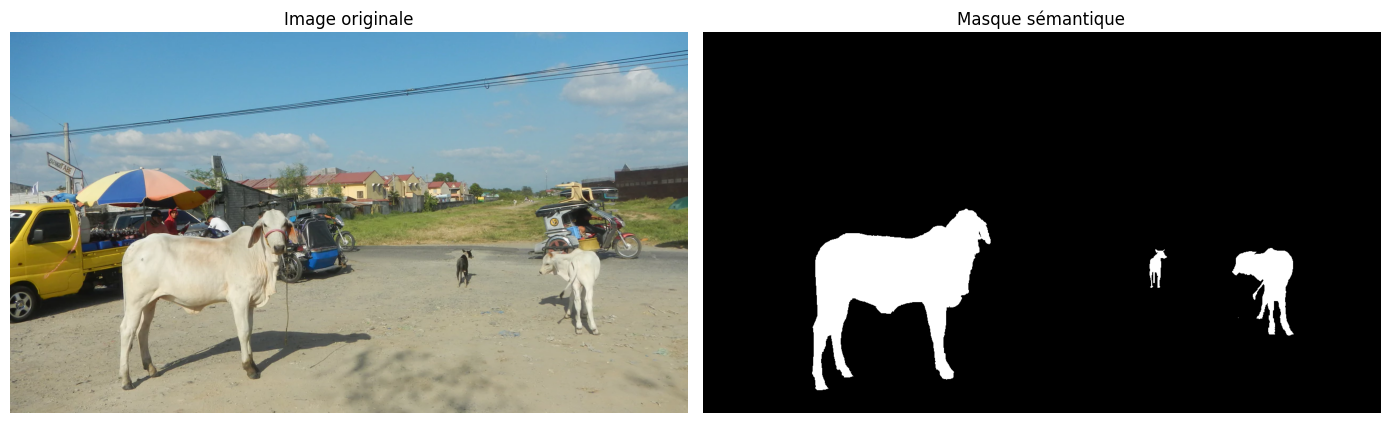

In [7]:


# Choisir une image
image_path = images[0]

# Construire le chemin du masque correspondant
image_name = os.path.splitext(os.path.basename(image_path))[0]

mask_path = os.path.join(
    frames_path,
    image_name + ".labels",
    "labels_semantic.png"
)

# Charger l'image et le masque
image = np.array(Image.open(image_path).convert("RGB"))
mask = np.array(Image.open(mask_path))

print("Image :", image.shape)
print("Masque :", mask.shape)
print("Valeurs présentes dans le masque :", np.unique(mask))

# Affichage côte à côte
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(image)
axes[0].set_title("Image originale")
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=2)
axes[1].set_title("Masque sémantique")
axes[1].axis("off")

plt.tight_layout()
plt.show()

<h2>Superposition des anomalies (masque) sur l'image originale</h2>

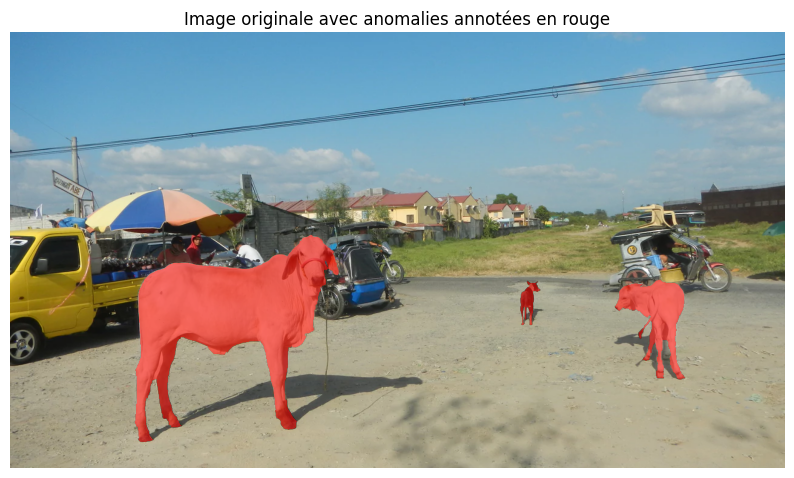

In [8]:
# Les pixels annotés comme anomalies
anomaly_region = mask == 2

# Afficher l'image originale
plt.figure(figsize=(10, 6))
plt.imshow(image)

# Superposer les anomalies en rouge
overlay = np.zeros((*mask.shape, 4))
overlay[anomaly_region] = [1, 0, 0, 0.55]

plt.imshow(overlay)
plt.title("Image originale avec anomalies annotées en rouge")
plt.axis("off")
plt.show()

<h2>Calcul et analyse des statistiques de pixels du masque</h2>

In [9]:
# Nombre total de pixels
total_pixels = mask.size

# Nombre de pixels correspondant aux anomalies
anomaly_pixels = np.sum(mask == 2)

# Nombre de pixels normaux
normal_pixels = np.sum(mask == 0)

print("Nombre total de pixels :", total_pixels)
print("Pixels normaux :", normal_pixels)
print("Pixels anormaux :", anomaly_pixels)

if total_pixels > 0:
    print(
        "Pourcentage de pixels anormaux :",
        round(100 * anomaly_pixels / total_pixels, 2),
        "%"
    )

print("Valeurs uniques du masque :", np.unique(mask))

Nombre total de pixels : 921600
Pixels normaux : 859783
Pixels anormaux : 61817
Pourcentage de pixels anormaux : 6.71 %
Valeurs uniques du masque : [0 2]


<h2>Calcul de la proportion globale d'anomalies sur l'ensemble du jeu de données</h2>

In [10]:
total_anomaly_pixels = 0
total_mask_pixels = 0
images_without_anomaly = 0

for image_path in images:
    name = os.path.splitext(os.path.basename(image_path))[0]

    path = os.path.join(
        frames_path,
        name + ".labels",
        "labels_semantic.png"
    )

    current_mask = np.array(Image.open(path))

    anomaly_count = np.sum(current_mask == 2)

    total_anomaly_pixels += anomaly_count
    total_mask_pixels += current_mask.size

    if anomaly_count == 0:
        images_without_anomaly += 1

print("Images analysées :", len(images))
print("Images sans pixels d'anomalie :", images_without_anomaly)

print(
    "Proportion globale d'anomalies :",
    round(100 * total_anomaly_pixels / total_mask_pixels, 3),
    "%"
)

Images analysées : 60
Images sans pixels d'anomalie : 0
Proportion globale d'anomalies : 9.85 %


<h2>Calcul de la répartition globale des pixels par classe</h2>

In [11]:

class_pixel_counts = Counter()
total_pixels = 0

for image_path, mask_path in image_pairs:
    mask = np.array(Image.open(mask_path))

    values, counts = np.unique(mask, return_counts=True)

    for value, count in zip(values, counts):
        class_pixel_counts[int(value)] += int(count)

    total_pixels += mask.size

print("Répartition globale des classes :\n")

for class_id, count in sorted(class_pixel_counts.items()):
    percentage = 100 * count / total_pixels

    print(
        f"Classe {class_id} : "
        f"{count:,} pixels, "
        f"{percentage:.3f} %"
    )


Répartition globale des classes :

Classe 0 : 49,849,587 pixels, 90.150 %
Classe 2 : 5,446,413 pixels, 9.850 %


<h3 style="color:red">L'analyse de la répartition des pixels montre un fort déséquilibre de classes, avec 90,15 % de fond/route (Classe 0) et seulement 9,85 % d'anomalies (Classe 2).</h3>

In [12]:
dimension_mismatches = []

for image_path in images:
    name = os.path.splitext(os.path.basename(image_path))[0]

    mask_path = os.path.join(
        frames_path,
        name + ".labels",
        "labels_semantic.png"
    )

    if not os.path.exists(mask_path):
        continue

    with Image.open(image_path) as img:
        image_size = img.size

    with Image.open(mask_path) as msk:
        mask_size = msk.size

    if image_size != mask_size:
        dimension_mismatches.append(
            (name, image_size, mask_size)
        )

print("Images avec des dimensions différentes :", dimension_mismatches)

Images avec des dimensions différentes : []


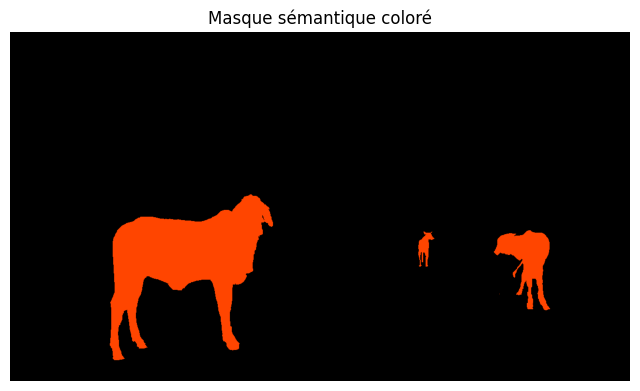

In [13]:
color_mask_path = os.path.join(
    frames_path,
    image_name + ".labels",
    "labels_semantic_color.png"
)

if os.path.exists(color_mask_path):
    color_mask = Image.open(color_mask_path)

    plt.figure(figsize=(8, 5))
    plt.imshow(color_mask)
    plt.title("Masque sémantique coloré")
    plt.axis("off")
    plt.show()

<h2>Distribution de la surface des anomalies par image et statistiques descriptives</h2>

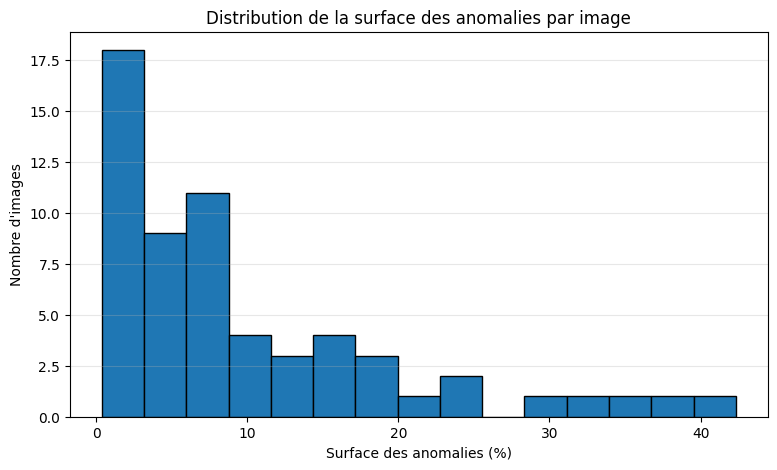

Surface moyenne : 9.85 %
Surface médiane : 6.623 %
Surface minimale : 0.375 %
Surface maximale : 42.329 %
Images avec moins de 0,1 % d'anomalies : 0


In [14]:
# Pourcentage de pixels anormaux dans chaque image
anomaly_percentages = []

for image_path, mask_path in image_pairs:

    # Charger le masque sémantique
    mask = np.array(Image.open(mask_path))

    # Vérifier que le masque est bien une image à une seule couche
    if mask.ndim != 2:
        raise ValueError(
            f"Masque non scalaire : {mask_path}, "
            f"dimensions = {mask.shape}"
        )

    # Créer un masque binaire : True pour une anomalie
    anomaly_mask = (mask == 2)

    # Calculer le pourcentage de pixels anormaux
    percentage = anomaly_mask.sum() / mask.size * 100

    anomaly_percentages.append(percentage)


# Afficher l'histogramme
plt.figure(figsize=(9, 5))

plt.hist(
    anomaly_percentages,
    bins=15,
    edgecolor="black"
)

plt.xlabel("Surface des anomalies (%)")
plt.ylabel("Nombre d'images")
plt.title("Distribution de la surface des anomalies par image")
plt.grid(axis="y", alpha=0.3)

plt.show()


# Quelques statistiques descriptives
print("Surface moyenne :", round(np.mean(anomaly_percentages), 3), "%")
print("Surface médiane :", round(np.median(anomaly_percentages), 3), "%")
print("Surface minimale :", round(np.min(anomaly_percentages), 3), "%")
print("Surface maximale :", round(np.max(anomaly_percentages), 3), "%")
print(
    "Images avec moins de 0,1 % d'anomalies :",
    sum(p < 0.1 for p in anomaly_percentages)
)

<h3 style="color:red">L'analyse de la distribution de la surface des anomalies met en évidence une asymétrie à droite (*right-skewed*), si celle-ci est confirmée par l'histogramme. La surface moyenne des anomalies représente 9,85 % de la surface totale des images, tandis que la médiane est de 6,623 %. Les proportions observées varient entre 0,375 % et 42,329 %, révélant une importante variabilité de la surface occupée par les anomalies d'une image à l'autre.

Ces résultats permettent de caractériser la répartition des anomalies dans le dataset et constituent une première étape pour mieux comprendre les données. Ils seront utiles pour orienter les choix de prétraitement et les décisions liées à la mise en place du modèle de segmentation.</h3>

<h2>Génération et affichage de la carte de chaleur (heatmap) des anomalies</h2>

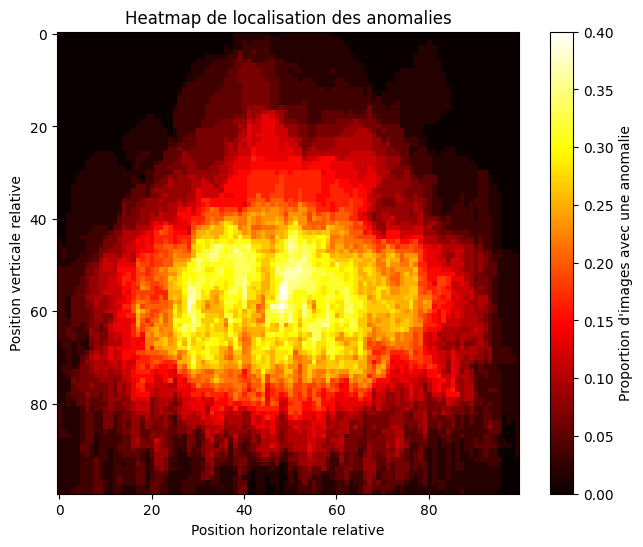

In [15]:

# Taille commune utilisée pour comparer les positions relatives
grid_size = (100, 100)

# Accumulateur des anomalies
heatmap = np.zeros(
    (grid_size[1], grid_size[0]),
    dtype=np.float64
)

for image_path, mask_path in image_pairs:

    # Charger le masque
    mask = Image.open(mask_path)

    # Redimensionner avec NEAREST pour conserver les classes
    mask = mask.resize(
        grid_size,
        resample=Image.Resampling.NEAREST
    )

    mask = np.array(mask)

    # Ajouter les pixels anormaux à la carte
    heatmap += (mask == 2)


# Afficher la heatmap
plt.figure(figsize=(8, 6))

plt.imshow(
    heatmap / max(len(image_pairs), 1),
    cmap="hot",
    origin="upper"
)

plt.colorbar(label="Proportion d'images avec une anomalie")
plt.title("Heatmap de localisation des anomalies")
plt.xlabel("Position horizontale relative")
plt.ylabel("Position verticale relative")

plt.show()

<h3 style="color:red">Cette carte de chaleur (heatmap) superpose l'ensemble des images pour visualiser la position spatiale des obstacles dans le cadre de la photo : la zone brillante (jaune/blanc) au centre montre que la quasi-totalité des anomalies se concentrent sur la chaussée, où près de 40 % des images en contiennent une, tandis que les zones sombres (noires) en haut confirment qu'aucune anomalie n'apparaît dans le ciel ou au niveau du décor haut (0 %).<h3>

In [16]:

image_modes = Counter()

for image_path, mask_path in image_pairs:

    with Image.open(image_path) as img:
        # Enregistrer le mode original avant toute conversion
        image_modes[img.mode] += 1


print("Modes d'image détectés :")

for mode, count in image_modes.items():
    print(f"{mode} : {count} image(s)")


# Vérifier les images possédant un canal alpha
alpha_modes = {"RGBA", "LA", "PA"}

images_with_alpha = []

for image_path, mask_path in image_pairs:

    with Image.open(image_path) as img:
        has_alpha = (
            "A" in img.getbands()
            or "transparency" in img.info
        )

        if has_alpha:
            images_with_alpha.append(image_path)


print("Images avec transparence :", len(images_with_alpha))

for path in images_with_alpha[:10]:
    print(os.path.basename(path))

Modes d'image détectés :
RGB : 60 image(s)
Images avec transparence : 0


<h3 style="color:red">L'analyse des modes d'images confirme que l'ensemble des 60 images du jeu de données utilise le format couleur standard RGB à 3 canaux, sans aucune couche de transparence (canal Alpha / RGBA). Cette parfaite homogénéité garantit qu'aucune conversion de format ou nettoyage préalable ne sera nécessaire avant d'injecter les images dans le pipeline de modélisation.</h3>

<h2>Comptage des composantes connexes et distribution des objets anormaux</h2>

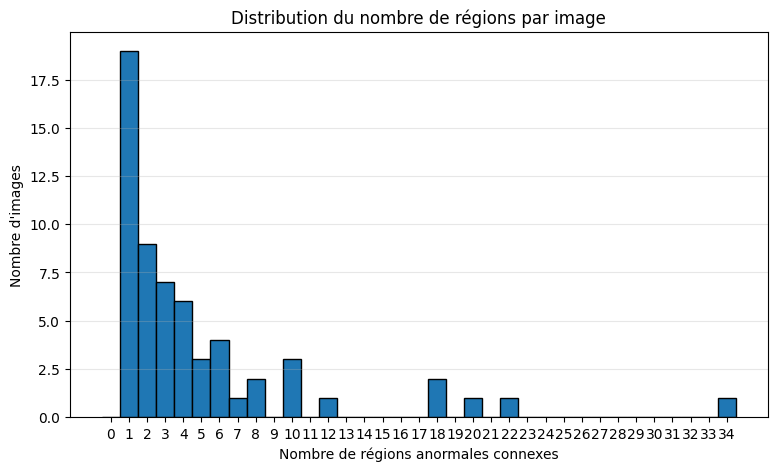

Nombre moyen de régions par image : 4.97


In [17]:

object_counts = []

# Connexité à 8 voisins : les pixels en diagonale sont aussi connectés
structure = np.ones((3, 3), dtype=int)

for image_path, mask_path in image_pairs:

    mask = np.array(Image.open(mask_path))

    # Sélectionner les pixels correspondant aux anomalies
    anomaly_mask = (mask == 2)

    # Identifier les régions connexes
    labeled_mask, number_of_regions = ndimage.label(
        anomaly_mask,
        structure=structure
    )

    object_counts.append(number_of_regions)


# Afficher la distribution du nombre de régions
plt.figure(figsize=(9, 5))

plt.hist(
    object_counts,
    bins=range(0, max(object_counts, default=0) + 2),
    align="left",
    edgecolor="black"
)

plt.xlabel("Nombre de régions anormales connexes")
plt.ylabel("Nombre d'images")
plt.title("Distribution du nombre de régions par image")
plt.xticks(range(0, max(object_counts, default=0) + 1))
plt.grid(axis="y", alpha=0.3)

plt.show()

print("Nombre moyen de régions par image :",
      round(float(np.mean(object_counts)), 2))

<h3 style="color:red">L'analyse de la fragmentation montre que la majorité des images contiennent un seul obstacle d'un seul bloc (19 images), avec une moyenne de 4,97 régions anormales par photo. Cependant, la présence de cas rares mais très complexes — où les anomalies sont éparpillées en plusieurs dizaines de petits morceaux (jusqu'à 34) — confirme que le modèle de segmentation devra être capable de gérer aussi bien des objets uniques et massifs que des obstacles fortement fragmentés.</h3>

<h2>Analyse et distribution du ratio d'aspect (largeur/hauteur) des anomalies</h2>

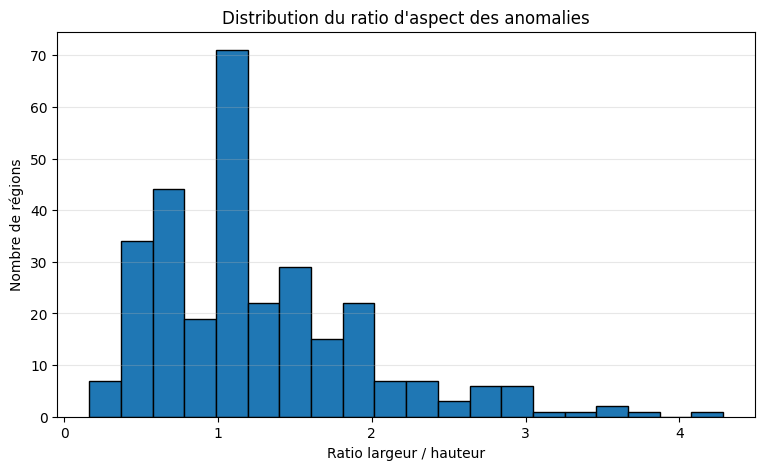

Ratio moyen : 1.25
Ratio médian : 1.0


In [18]:


aspect_ratios = []

structure = np.ones((3, 3), dtype=int)

for image_path, mask_path in image_pairs:

    mask = np.array(Image.open(mask_path))
    anomaly_mask = (mask == 2)

    # Identifier les régions connexes
    labeled_mask, number_of_regions = ndimage.label(
        anomaly_mask,
        structure=structure
    )

    # Extraire les boîtes englobantes de chaque région
    regions = ndimage.find_objects(labeled_mask)

    for region in regions:

        if region is None:
            continue

        # Dimensions de la boîte englobante
        height = region[0].stop - region[0].start
        width = region[1].stop - region[1].start

        if height > 0:
            aspect_ratios.append(width / height)


# Afficher la distribution des ratios
plt.figure(figsize=(9, 5))

plt.hist(
    aspect_ratios,
    bins=20,
    edgecolor="black"
)

plt.xlabel("Ratio largeur / hauteur")
plt.ylabel("Nombre de régions")
plt.title("Distribution du ratio d'aspect des anomalies")
plt.grid(axis="y", alpha=0.3)

plt.show()

if aspect_ratios:
    print("Ratio moyen :",
          round(float(np.mean(aspect_ratios)), 2))
    print("Ratio médian :",
          round(float(np.median(aspect_ratios)), 2))

<h3 style="color:red">L'analyse du ratio d'aspect ($\frac{\text{largeur}}{\text{hauteur}}$) montre que la majorité des régions anormales présentent des proportions équilibrées ou carrées, comme l'indique le pic principal à 1,0 (médiane = 1,0). La moyenne s'élève à 1,25 en raison d'une traînée d'obstacles étalés horizontalement sur la chaussée (ratios allant jusqu'à 4), tandis que les formes très étirées en hauteur (ratios < 1) restent minoritaires.</h3>

Le Pretraitement

In [19]:
import re, json, random
from collections import defaultdict

random.seed(42)

groups = defaultdict(list)
for img_path, mask_path in image_pairs:
    name = os.path.splitext(os.path.basename(img_path))[0]
    cat = re.match(r"[A-Za-z]+", name).group()
    groups[cat].append((img_path, mask_path))

split = {"train": [], "val": [], "test": []}
for cat, items in groups.items():
    random.shuffle(items)
    n = len(items)
    if n < 3:
        split["train"] += items
        continue
    n_test = max(1, round(0.15 * n))
    n_val = max(1, round(0.15 * n))
    split["test"] += items[:n_test]
    split["val"] += items[n_test:n_test + n_val]
    split["train"] += items[n_test + n_val:]

for k, v in split.items():
    print(k, len(v))

# Manifeste à partager avec le groupe
manifest = {k: [os.path.basename(p[0]) for p in v] for k, v in split.items()}
with open("split_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

train 40
val 10
test 10


<h3 style="color:red">Les 60 images sont réparties en 40 pour l'entraînement (train), 10 pour la validation (val) et 10 pour le test. Le découpage est fait par catégorie (animals, cones, obstacles…) avec la seed 42, pour que chaque catégorie soit présente dans les trois ensembles. La liste est sauvegardée dans <code>split_manifest.json</code> pour que Walid et le groupe utilisent exactement les mêmes images. Le test n'est pas utilisé avant la comparaison finale. <br><br>Limite : le découpage se base sur le nom de la catégorie, donc deux images d'une même scène pourraient se retrouver dans des ensembles différents.</h3>

In [20]:
%pip install albumentations

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
%pip install torch torchvision
import albumentations as A
from albumentations.pytorch import ToTensorV2

H, W = 288, 512
mean, std = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

train_tf = A.Compose([
    A.Resize(H, W, interpolation=1, mask_interpolation=0),  # image bilinéaire, masque nearest
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=10,
                       border_mode=0, p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.Normalize(mean=mean, std=std),
    ToTensorV2(),
])

eval_tf = A.Compose([
    A.Resize(H, W, interpolation=1, mask_interpolation=0),
    A.Normalize(mean=mean, std=std),
    ToTensorV2(),
])

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
<user home>\AppData\Local\Programs\Python\Python314\Lib\site-packages\albumentations\core\validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


<h3 style="color:red">Toutes les images sont redimensionnées en 288×512 et normalisées avec la moyenne et l'écart-type d'ImageNet (nécessaire pour l'encodeur ResNet18 plus loin). Les masques sont redimensionnés avec le mode <i>nearest</i> pour garder uniquement des valeurs entières. Pour l'entraînement seulement, on ajoute des variations aléatoires (miroir, petit décalage/rotation/zoom, luminosité) qui s'appliquent en même temps à l'image et à son masque. La validation et le test ne reçoivent aucune augmentation. L'avertissement sur <i>ShiftScaleRotate</i> est sans conséquence : la fonction fonctionne, elle est seulement remplacée par <i>Affine</i> dans les versions récentes.</h3>

In [22]:
import torch
from torch.utils.data import Dataset, DataLoader

class RoadAnomalyDataset(Dataset):
    def __init__(self, pairs, transform):
        self.pairs = pairs
        self.transform = transform

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, i):
        img_path, mask_path = self.pairs[i]
        image = np.array(Image.open(img_path).convert("RGB"))
        mask = (np.array(Image.open(mask_path)) == 2).astype(np.uint8)  # binaire 0/1
        out = self.transform(image=image, mask=mask)
        return out["image"], out["mask"].unsqueeze(0).float()  # (3,H,W), (1,H,W)

train_ds = RoadAnomalyDataset(split["train"], train_tf)
val_ds   = RoadAnomalyDataset(split["val"],   eval_tf)
test_ds  = RoadAnomalyDataset(split["test"],  eval_tf)

train_loader = DataLoader(train_ds, batch_size=4, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=4)
test_loader  = DataLoader(test_ds,  batch_size=4)

x, y = next(iter(train_loader))
print(x.shape, y.shape, y.unique())  # attendu : [4,3,288,512] [4,1,288,512] tensor([0.,1.])

torch.Size([4, 3, 288, 512]) torch.Size([4, 1, 288, 512]) tensor([0., 1.])


<h3 style="color:red">Le masque est transformé en masque binaire : 1 pour les pixels d'anomalie (classe 2) et 0 pour tout le reste. Le DataLoader fournit des lots de 4 images de forme [4, 3, 288, 512] et des masques de forme [4, 1, 288, 512] ne contenant que 0 et 1. Les dimensions et les valeurs sont donc correctes pour entraîner un modèle de segmentation binaire.</h3>

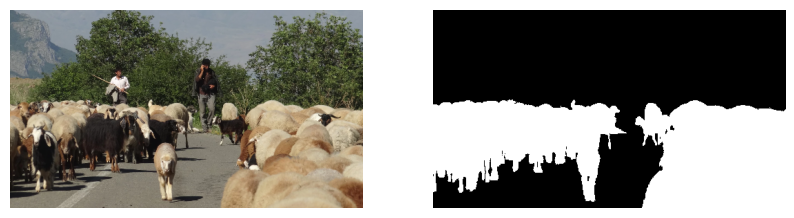

In [23]:
img = x[0].permute(1, 2, 0).numpy() * std + mean
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img.clip(0, 1)); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(y[0, 0], cmap="gray"); plt.axis("off")
plt.show()

<h3 style="color:red">Après l'augmentation, le masque reste bien placé sur les animaux : l'image et le masque ont subi exactement les mêmes transformations. Le prétraitement est donc correct. Cet exemple montre aussi une difficulté du dataset : un troupeau entier est une grande zone d'anomalie avec des contours très découpés, ce qui est difficile à segmenter.</h3>

In [24]:
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

def block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
    )

class CNNBaseline(nn.Module):
    def __init__(self):
        super().__init__()
        # Encodeur : on rétrécit (canaux doublés : 32-64-128)
        self.enc1 = nn.Sequential(block(3, 32),   nn.MaxPool2d(2))    # 32 x 144 x 256
        self.enc2 = nn.Sequential(block(32, 64),  nn.MaxPool2d(2))    # 64 x 72 x 128
        self.enc3 = nn.Sequential(block(64, 128), nn.MaxPool2d(2))    # 128 x 36 x 64
        # Décodeur : on ré-agrandit (toujours SANS skip connections)
        self.dec1 = nn.Sequential(nn.ConvTranspose2d(128, 64, 2, stride=2), block(64, 64))  # 64 x 72 x 128
        self.dec2 = nn.Sequential(nn.ConvTranspose2d(64, 32, 2, stride=2),  block(32, 32))  # 32 x 144 x 256
        self.dec3 = nn.Sequential(nn.ConvTranspose2d(32, 16, 2, stride=2),  block(16, 16))  # 16 x 288 x 512
        self.out = nn.Conv2d(16, 1, 1)                                                      # 1 x 288 x 512

    def forward(self, x):
        x = self.enc3(self.enc2(self.enc1(x)))
        x = self.dec3(self.dec2(self.dec1(x)))
        return self.out(x)   # logits (pas de sigmoid ici)

# Loss = BCE + Dice (à cause du déséquilibre 90/10)
bce = nn.BCEWithLogitsLoss()

def dice_loss(logits, targets, eps=1.0):
    p = torch.sigmoid(logits)
    inter = (p * targets).sum(dim=(1, 2, 3))
    union = p.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
    return 1 - ((2 * inter + eps) / (union + eps)).mean()

def criterion(logits, targets):
    return bce(logits, targets) + dice_loss(logits, targets)

@torch.no_grad()
def evaluate(model, loader, thr=0.5):
    model.eval()
    tp = fp = fn = 0.0
    total_loss, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += criterion(logits, y).item() * x.size(0)
        n += x.size(0)
        pred = (torch.sigmoid(logits) > thr).float()
        tp += (pred * y).sum().item()
        fp += (pred * (1 - y)).sum().item()
        fn += ((1 - pred) * y).sum().item()
    eps = 1e-7
    precision = tp / (tp + fp + eps)
    recall    = tp / (tp + fn + eps)
    f1        = 2 * precision * recall / (precision + recall + eps)
    iou       = tp / (tp + fp + fn + eps)
    dice      = 2 * tp / (2 * tp + fp + fn + eps)
    return {"loss": total_loss / n, "precision": precision, "recall": recall,
            "f1": f1, "iou": iou, "dice": dice}

@torch.no_grad()
def best_threshold(model, loader, grid=np.arange(0.10, 0.91, 0.05)):
    """Cherche sur la VALIDATION le seuil qui maximise l'IoU."""
    model.eval()
    P, Y = [], []
    for x, y in loader:
        P.append(torch.sigmoid(model(x.to(device))).cpu())
        Y.append(y)
    P, Y = torch.cat(P), torch.cat(Y)
    best_iou, best_thr = -1.0, 0.5
    for t in grid:
        pred = (P > t).float()
        inter = (pred * Y).sum().item()
        union = ((pred + Y) > 0).float().sum().item()
        iou = inter / (union + 1e-7)
        if iou > best_iou:
            best_iou, best_thr = iou, float(t)
    return best_iou, best_thr

model = CNNBaseline().to(device)
print(sum(p.numel() for p in model.parameters()), "paramètres")

Device : cpu
185553 paramètres


<h3 style="color:red">Le CNN baseline est un encodeur-décodeur à 3 niveaux (canaux 32-64-128) avec 185 553 paramètres. Il réduit l'image puis la ré-agrandit pour dessiner le masque. Il n'a pas de skip connections, ce qui le garde simple comme baseline avant le U-Net. La loss BCE + Dice compense le déséquilibre des classes (environ 90 % de fond contre 10 % d'anomalies). L'entraînement se fait sur CPU.</h3>

In [25]:
import time

torch.manual_seed(42)
EPOCHS, LR = 80, 1e-3
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)  # le LR baisse progressivement

history = {"train_loss": [], "val_loss": [], "val_iou": [], "val_dice": []}
best_iou = 0.0
start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    running, n = 0.0, 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        running += loss.item() * x.size(0)
        n += x.size(0)

    scheduler.step()
    val = evaluate(model, val_loader)
    history["train_loss"].append(running / n)
    history["val_loss"].append(val["loss"])
    history["val_iou"].append(val["iou"])
    history["val_dice"].append(val["dice"])

    if val["iou"] > best_iou:            # meilleur modèle sur la validation
        best_iou = val["iou"]
        torch.save(model.state_dict(), "cnn_baseline_best.pth")

    print(f"Epoch {epoch:02d} | train {running/n:.3f} | val {val['loss']:.3f} "
          f"| IoU {val['iou']:.3f} | Dice {val['dice']:.3f}")

print(f"Durée : {(time.time()-start)/60:.1f} min | meilleur IoU val : {best_iou:.3f}")
print(f"Config : seed=42, résolution={H}x{W}, batch=4, epochs={EPOCHS}, lr={LR} (AdamW wd=1e-4, CosineAnnealingLR)")

Epoch 01 | train 1.461 | val 1.461 | IoU 0.000 | Dice 0.000
Epoch 02 | train 1.349 | val 1.471 | IoU 0.214 | Dice 0.352
Epoch 03 | train 1.292 | val 1.510 | IoU 0.198 | Dice 0.330
Epoch 04 | train 1.254 | val 1.458 | IoU 0.218 | Dice 0.358
Epoch 05 | train 1.241 | val 1.354 | IoU 0.231 | Dice 0.376
Epoch 06 | train 1.233 | val 1.340 | IoU 0.230 | Dice 0.374
Epoch 07 | train 1.213 | val 1.369 | IoU 0.207 | Dice 0.343
Epoch 08 | train 1.198 | val 1.254 | IoU 0.252 | Dice 0.403
Epoch 09 | train 1.167 | val 1.318 | IoU 0.208 | Dice 0.345
Epoch 10 | train 1.151 | val 1.237 | IoU 0.241 | Dice 0.388
Epoch 11 | train 1.143 | val 1.209 | IoU 0.245 | Dice 0.393
Epoch 12 | train 1.146 | val 1.215 | IoU 0.240 | Dice 0.387
Epoch 13 | train 1.127 | val 1.216 | IoU 0.232 | Dice 0.377
Epoch 14 | train 1.115 | val 1.177 | IoU 0.228 | Dice 0.371
Epoch 15 | train 1.098 | val 1.189 | IoU 0.240 | Dice 0.387
Epoch 16 | train 1.089 | val 1.251 | IoU 0.239 | Dice 0.386
Epoch 17 | train 1.070 | val 1.164 | IoU

<h3 style="color:red">Le modèle a été entraîné pendant 80 epochs (22,1 minutes) avec AdamW et un learning rate qui baisse progressivement (cosinus). La loss d'entraînement passe de 1,46 à environ 0,80, donc le modèle apprend. Le meilleur IoU de validation est de 0,266 et ce modèle est sauvegardé dans <code>cnn_baseline_best.pth</code>. L'IoU de la première epoch est de 0 : le modèle ne prédit encore aucune anomalie.</h3>

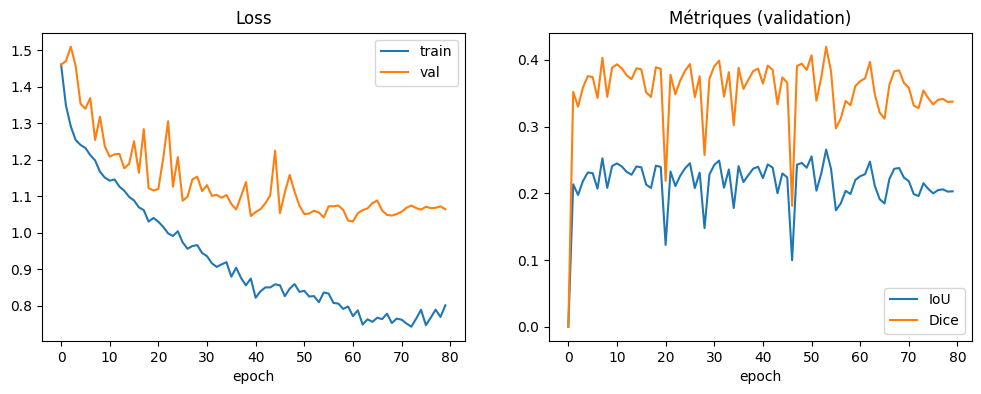

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["train_loss"], label="train")
ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["val_iou"], label="IoU")
ax[1].plot(history["val_dice"], label="Dice")
ax[1].set_title("Métriques (validation)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

<h3 style="color:red">La loss d'entraînement baisse régulièrement (de 1,46 à environ 0,80), mais celle de validation se stabilise vers 1,05 à partir de l'epoch 45 environ. L'écart d'environ 0,3 montre un début de surapprentissage : avec seulement 40 images, le modèle mémorise les images d'entraînement. L'IoU de validation reste entre 0,18 et 0,27 sans progresser après les premières epochs, avec des chutes brutales (vers 0,10 aux epochs 20 et 46). Ces variations viennent probablement de la validation de seulement 10 images, où une seule image difficile change beaucoup le score. Entraîner plus longtemps n'apporte donc rien.</h3>

Seuil choisi sur validation : 0.40 (IoU 0.268)
Avec seuil 0.5 : {'loss': 1.0558, 'precision': 0.3577, 'recall': 0.5076, 'f1': 0.4197, 'iou': 0.2656, 'dice': 0.4197}
Avec seuil 0.40 : {'loss': 1.0558, 'precision': 0.3375, 'recall': 0.5651, 'f1': 0.4226, 'iou': 0.2679, 'dice': 0.4226}


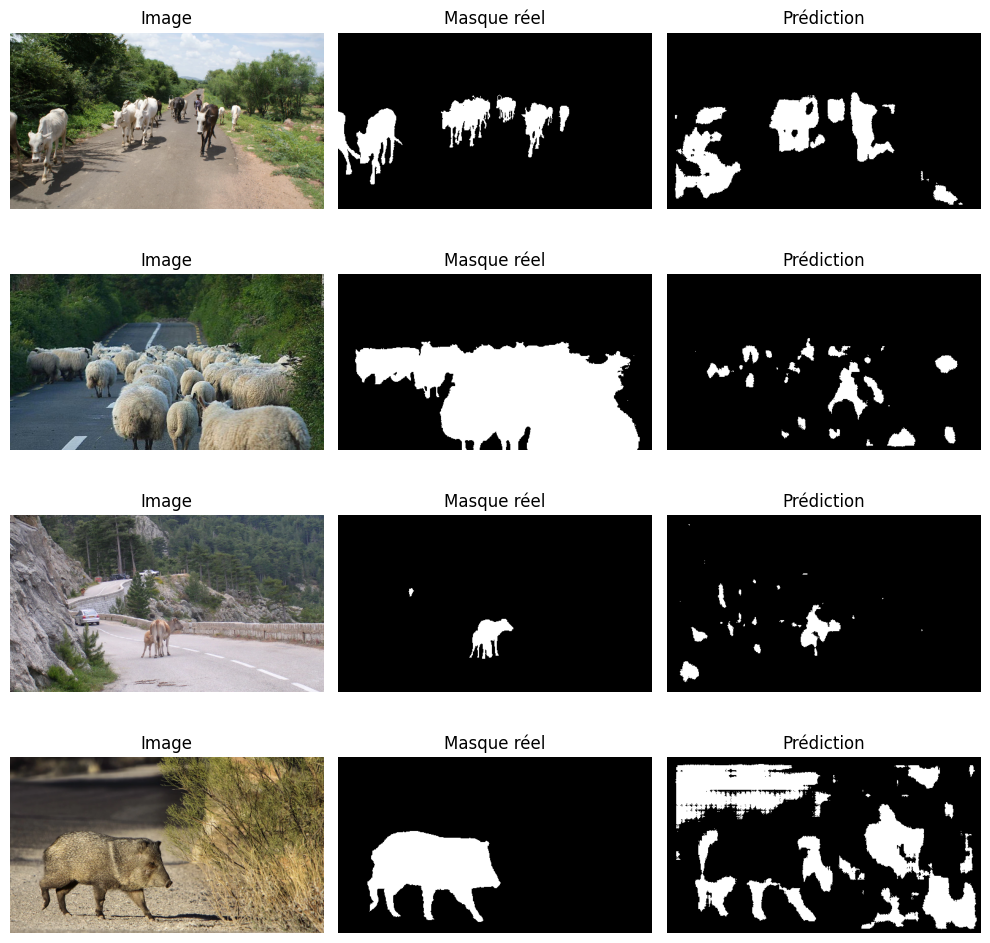

In [27]:
model.load_state_dict(torch.load("cnn_baseline_best.pth"))
# Seuil choisi sur la VALIDATION (jamais sur le test), puis figé pour le test final
iou_thr, THR = best_threshold(model, val_loader)
print(f"Seuil choisi sur validation : {THR:.2f} (IoU {iou_thr:.3f})")
with open("cnn_threshold.json", "w") as f:
    json.dump({"threshold": THR}, f)

print("Avec seuil 0.5 :", {k: round(v, 4) for k, v in evaluate(model, val_loader, thr=0.5).items()})
res = evaluate(model, val_loader, thr=THR)
print(f"Avec seuil {THR:.2f} :", {k: round(v, 4) for k, v in res.items()})

model.eval()
x, y = next(iter(val_loader))
with torch.no_grad():
    pred = (torch.sigmoid(model(x.to(device))) > THR).float().cpu()

mean_t, std_t = np.array(mean), np.array(std)
fig, ax = plt.subplots(4, 3, figsize=(10, 10))
for i in range(4):
    img = (x[i].permute(1, 2, 0).numpy() * std_t + mean_t).clip(0, 1)
    ax[i, 0].imshow(img);          ax[i, 0].set_title("Image")
    ax[i, 1].imshow(y[i, 0], cmap="gray");    ax[i, 1].set_title("Masque réel")
    ax[i, 2].imshow(pred[i, 0], cmap="gray"); ax[i, 2].set_title("Prédiction")
    for a in ax[i]: a.axis("off")
plt.tight_layout(); plt.show()

<h3 style="color:red">Sur la validation, le meilleur seuil est 0,40 (IoU 0,268), contre 0,5 par défaut (IoU 0,266) : le gain est négligeable. Avec 0,40 : Precision 0,338, Recall 0,565, F1/Dice 0,423. Un seuil plus bas détecte plus d'anomalies (recall plus élevé) mais fait plus de faux positifs. <br><br>Sur les images : le modèle repère à peu près la zone des animaux (lignes 1 et 3), mais les contours sont flous. Il rate une grande partie du grand troupeau de moutons (ligne 2, faux négatifs) et prédit des anomalies sur la végétation, les rochers et le fond (lignes 3 et 4, faux positifs). C'est cohérent avec un petit CNN sans skip connections et sans pré-entraînement. Le test n'a pas été utilisé.</h3>

In [28]:
import numpy as np
from PIL import Image
from collections import Counter

for name, pairs in split.items():
    cats = Counter(re.match(r"[A-Za-z]+", os.path.basename(p[0])).group() for p in pairs)
    areas = [(np.array(Image.open(m)) == 2).mean() * 100 for _, m in pairs]
    print(f"{name:5s} | {len(pairs)} images | anomalie moyenne {np.mean(areas):.1f}% "
          f"| médiane {np.median(areas):.1f}%")
    print("      catégories :", dict(cats))

train | 40 images | anomalie moyenne 9.7% | médiane 6.6%
      catégories : {'animals': 21, 'cones': 6, 'lost': 1, 'obstacles': 11, 'vehicle': 1}
val   | 10 images | anomalie moyenne 11.2% | médiane 6.5%
      catégories : {'animals': 5, 'cones': 1, 'lost': 1, 'obstacles': 2, 'vehicle': 1}
test  | 10 images | anomalie moyenne 9.2% | médiane 7.9%
      catégories : {'animals': 5, 'cones': 1, 'lost': 1, 'obstacles': 2, 'vehicle': 1}


<h3 style="color:red">Les trois ensembles ont des proportions d'anomalies proches : moyenne de 9,7 % (train), 11,2 % (val) et 9,2 % (test), avec des médianes comparables. La catégorie « animals » domine (21 images sur 40 en train), alors que « lost » et « vehicle » n'ont qu'une image par ensemble : les résultats sur ces deux catégories ne sont pas fiables. La validation et le test ne comptent que 10 images chacun, donc les métriques ont une grande marge d'incertitude.</h3>

In [30]:
from torchvision import models

class ResNetCNN(nn.Module):
    def __init__(self):
        super().__init__()
        r = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        self.encoder = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool,
                                     r.layer1, r.layer2, r.layer3, r.layer4)  # 512 x 9 x 16

        def up(cin, cout):
            return nn.Sequential(nn.ConvTranspose2d(cin, cout, 2, stride=2), block(cout, cout))

        self.decoder = nn.Sequential(up(512, 256), up(256, 128), up(128, 64),
                                     up(64, 32), up(32, 16))                  # 16 x 288 x 512
        self.out = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        return self.out(self.decoder(self.encoder(x)))

    def train(self, mode=True):
        super().train(mode)
        self.encoder.eval()   # BatchNorm de l'encodeur figée (batch de 4 = trop petit)
        return self

model_in = ResNetCNN().to(device)
for p in model_in.encoder.parameters():
    p.requires_grad = False   # étape 1 : encodeur gelé

print(sum(p.numel() for p in model_in.parameters() if p.requires_grad), "paramètres entraînables")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to <user home>/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


1486033 paramètres entraînables


<h3 style="color:red">Expérience additionnelle : l'encodeur est un ResNet18 pré-entraîné sur ImageNet (environ 11 millions de paramètres), suivi d'un décodeur simple sans skip connections. Dans la première étape, l'encodeur est gelé et seuls les 1 486 033 paramètres du décodeur sont entraînés. Ce n'est plus la baseline : le modèle est présenté à part, comme expérience complémentaire, pour mesurer l'effet du pré-entraînement.</h3>

In [31]:
torch.manual_seed(42)
hist_in = {"train_loss": [], "val_loss": [], "val_iou": [], "val_dice": []}
best_iou_in = 0.0

def run_stage(n_epochs, optimizer, stage):
    global best_iou_in
    for epoch in range(1, n_epochs + 1):
        model_in.train()
        running, n = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model_in(x), y)
            loss.backward()
            optimizer.step()
            running += loss.item() * x.size(0)
            n += x.size(0)
        val = evaluate(model_in, val_loader)
        hist_in["train_loss"].append(running / n)
        hist_in["val_loss"].append(val["loss"])
        hist_in["val_iou"].append(val["iou"])
        hist_in["val_dice"].append(val["dice"])
        if val["iou"] > best_iou_in:
            best_iou_in = val["iou"]
            torch.save(model_in.state_dict(), "cnn_imagenet_best.pth")
        print(f"[{stage}] Epoch {epoch:02d} | train {running/n:.3f} | val {val['loss']:.3f} "
              f"| IoU {val['iou']:.3f} | Dice {val['dice']:.3f}")

start = time.time()

# Étape 1 : encodeur gelé, on entraîne seulement le décodeur
opt1 = torch.optim.AdamW(list(model_in.decoder.parameters()) + list(model_in.out.parameters()),
                         lr=1e-3, weight_decay=1e-4)
run_stage(25, opt1, "gelé")

# Étape 2 : on dégèle layer4, avec un learning rate plus faible pour l'encodeur
for p in model_in.encoder[7].parameters():
    p.requires_grad = True
opt2 = torch.optim.AdamW([
    {"params": model_in.encoder[7].parameters(), "lr": 1e-4},
    {"params": list(model_in.decoder.parameters()) + list(model_in.out.parameters()), "lr": 3e-4},
], weight_decay=1e-4)
run_stage(15, opt2, "layer4")

print(f"Durée : {(time.time()-start)/60:.1f} min | meilleur IoU val : {best_iou_in:.3f}")
print("Config : seed=42, ResNet18 ImageNet, 25 epochs gelé + 15 epochs layer4, batch=4, AdamW")

[gelé] Epoch 01 | train 1.358 | val 1.471 | IoU 0.342 | Dice 0.510
[gelé] Epoch 02 | train 1.221 | val 1.532 | IoU 0.254 | Dice 0.405
[gelé] Epoch 03 | train 1.153 | val 1.205 | IoU 0.412 | Dice 0.583
[gelé] Epoch 04 | train 1.092 | val 1.194 | IoU 0.407 | Dice 0.579
[gelé] Epoch 05 | train 1.062 | val 1.122 | IoU 0.458 | Dice 0.628
[gelé] Epoch 06 | train 1.054 | val 1.113 | IoU 0.388 | Dice 0.559
[gelé] Epoch 07 | train 1.025 | val 1.046 | IoU 0.395 | Dice 0.567
[gelé] Epoch 08 | train 0.988 | val 1.073 | IoU 0.380 | Dice 0.551
[gelé] Epoch 09 | train 0.947 | val 1.063 | IoU 0.407 | Dice 0.578
[gelé] Epoch 10 | train 0.937 | val 1.034 | IoU 0.407 | Dice 0.578
[gelé] Epoch 11 | train 0.922 | val 1.040 | IoU 0.314 | Dice 0.478
[gelé] Epoch 12 | train 0.880 | val 0.983 | IoU 0.417 | Dice 0.589
[gelé] Epoch 13 | train 0.863 | val 0.952 | IoU 0.431 | Dice 0.602
[gelé] Epoch 14 | train 0.859 | val 1.035 | IoU 0.420 | Dice 0.591
[gelé] Epoch 15 | train 0.824 | val 1.058 | IoU 0.249 | Dice 0

<h3 style="color:red">Entraînement en deux étapes (10,7 minutes). Étape 1, encodeur gelé (25 epochs) : l'IoU de validation oscille entre 0,25 et 0,46 (maximum 0,458 à l'epoch 5), déjà bien au-dessus du CNN de zéro. Étape 2, dégel du bloc <i>layer4</i> avec un learning rate plus faible (15 epochs) : l'IoU monte jusqu'à 0,529 à l'epoch 14, avec une loss de validation de 0,70. Le dernier epoch redescend à 0,462, ce qui montre que le score fluctue d'un epoch à l'autre. Le meilleur epoch étant choisi sur la validation de 10 images, 0,529 est un peu optimiste.</h3>

In [32]:
model_in.load_state_dict(torch.load("cnn_imagenet_best.pth"))

iou_thr, THR_IN = best_threshold(model_in, val_loader)
print(f"Seuil choisi sur validation : {THR_IN:.2f} (IoU {iou_thr:.3f})")
with open("cnn_imagenet_threshold.json", "w") as f:
    json.dump({"threshold": THR_IN}, f)

print("Seuil 0.5 :", {k: round(v, 4) for k, v in evaluate(model_in, val_loader, thr=0.5).items()})
print(f"Seuil {THR_IN:.2f} :", {k: round(v, 4) for k, v in evaluate(model_in, val_loader, thr=THR_IN).items()})

Seuil choisi sur validation : 0.15 (IoU 0.561)
Seuil 0.5 : {'loss': 0.6986, 'precision': 0.7779, 'recall': 0.6225, 'f1': 0.6916, 'iou': 0.5286, 'dice': 0.6916}
Seuil 0.15 : {'loss': 0.6986, 'precision': 0.7081, 'recall': 0.73, 'f1': 0.7189, 'iou': 0.5611, 'dice': 0.7189}


<h3 style="color:red">Le seuil choisi sur la validation est 0,15 (IoU 0,561). Avec 0,5 : Precision 0,778, Recall 0,623, F1/Dice 0,692, IoU 0,529. Avec 0,15 : Precision 0,708, Recall 0,730, F1/Dice 0,719, IoU 0,561. Le modèle est peu confiant sur les anomalies, donc un seuil bas récupère plus de pixels anormaux au prix d'un peu de précision. Le gain de 0,529 à 0,561 est modeste et pourrait ne pas se retrouver sur le test. Le seuil est sauvegardé dans <code>cnn_imagenet_threshold.json</code> et sera réutilisé tel quel pour le test.</h3>

<h2>Courbes d'entraînement du CNN + ResNet18 ImageNet</h2>

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist_in["train_loss"], label="train")
ax[0].plot(hist_in["val_loss"], label="val")
ax[0].axvline(24.5, color="gray", linestyle="--", label="dégel de layer4")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()

ax[1].plot(hist_in["val_iou"], label="IoU")
ax[1].plot(hist_in["val_dice"], label="Dice")
ax[1].axvline(24.5, color="gray", linestyle="--", label="dégel de layer4")
ax[1].set_title("Métriques (validation)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()


<h3 style="color:red">La loss d'entraînement baisse de 1,36 à environ 0,48 et celle de validation de 1,47 à environ 0,70 : le modèle apprend et généralise mieux que le CNN de zéro (loss de validation d'environ 1,06). L'IoU de validation oscille beaucoup d'une epoch à l'autre, ce qui est normal avec seulement 10 images de validation. Après le dégel de <i>layer4</i> (ligne en pointillés), la loss de validation continue de baisser et l'IoU atteint son meilleur niveau (0,529).</h3>

<h2>Prédictions : CNN v2 contre CNN + ImageNet (validation)</h2>

In [ ]:
model.eval(); model_in.eval()
mean_t, std_t = np.array(mean), np.array(std)

x, y = next(iter(val_loader))   # mêmes images que l'évaluation du CNN v2
with torch.no_grad():
    p_v2 = (torch.sigmoid(model(x.to(device))) > THR).float().cpu()        # CNN v2
    p_in = (torch.sigmoid(model_in(x.to(device))) > THR_IN).float().cpu()  # CNN + ImageNet

titres = ["Image", "Masque réel", f"CNN v2 (seuil {THR:.2f})", f"CNN + ImageNet (seuil {THR_IN:.2f})"]
fig, ax = plt.subplots(4, 4, figsize=(14, 9))
for i in range(4):
    img = (x[i].permute(1, 2, 0).numpy() * std_t + mean_t).clip(0, 1)
    for j, im in enumerate([img, y[i, 0], p_v2[i, 0], p_in[i, 0]]):
        ax[i, j].imshow(im, cmap=None if j == 0 else "gray")
        ax[i, j].axis("off")
        if i == 0:
            ax[i, j].set_title(titres[j])
plt.tight_layout(); plt.show()


<h3 style="color:red">[À compléter après exécution : décrire où le modèle ImageNet fait mieux que le CNN v2 (contours des animaux, grand troupeau de moutons, moins de faux positifs sur la végétation et les rochers) et quelles erreurs il garde (faux positifs ou faux négatifs restants).]</h3>

<h2>Résultats par image, taille des anomalies et vitesse d'inférence</h2>

In [ ]:
@torch.no_grad()
def metrics_par_image(m, loader, thr):
    m.eval(); rows, k = [], 0
    for x, y in loader:   # val_loader n'est pas mélangé : l'ordre suit split["val"]
        p = (torch.sigmoid(m(x.to(device))) > thr).float().cpu()
        for i in range(x.size(0)):
            tp = (p[i] * y[i]).sum().item()
            fp = (p[i] * (1 - y[i])).sum().item()
            fn = ((1 - p[i]) * y[i]).sum().item()
            rows.append({"image": os.path.basename(split["val"][k][0]),
                         "anom": 100 * y[i].mean().item(),
                         "iou": tp / (tp + fp + fn + 1e-7),
                         "dice": 2 * tp / (2 * tp + fp + fn + 1e-7)})
            k += 1
    return rows

r_v2 = metrics_par_image(model, val_loader, THR)
r_in = metrics_par_image(model_in, val_loader, THR_IN)

print(f"{'image':28s} {'anomalie %':>10s} {'IoU v2':>8s} {'IoU ImageNet':>13s}")
for a, b in zip(r_v2, r_in):
    print(f"{a['image'][:28]:28s} {a['anom']:10.1f} {a['iou']:8.3f} {b['iou']:13.3f}")

# Petites contre grandes anomalies (séparées par la médiane de la surface)
med = np.median([r["anom"] for r in r_in])
for nom, rows in [("CNN v2", r_v2), ("CNN + ImageNet", r_in)]:
    petit = np.mean([r["iou"] for r in rows if r["anom"] <= med])
    grand = np.mean([r["iou"] for r in rows if r["anom"] > med])
    print(f"{nom:15s} IoU moyen : petites anomalies {petit:.3f} | grandes anomalies {grand:.3f}")

# Vitesse d'inférence (une image, {H}x{W})
def latence(m, n=20):
    m.eval(); x = torch.randn(1, 3, H, W).to(device)
    with torch.no_grad():
        for _ in range(3): m(x)          # échauffement
        t0 = time.time()
        for _ in range(n): m(x)
        if device.type == "cuda": torch.cuda.synchronize()
    dt = (time.time() - t0) / n
    return dt * 1000, 1 / dt

for nom, m in [("CNN v2", model), ("CNN + ImageNet", model_in)]:
    ms, fps = latence(m)
    print(f"{nom:15s} latence : {ms:.0f} ms/image | {fps:.1f} FPS ({device})")


<h3 style="color:red">Les 60 images du dataset contiennent toutes des pixels d'anomalie (0 image sans anomalie), donc l'évaluation par image n'a pas de cas particulier à traiter. Le tableau compare l'IoU de chaque image de validation pour les deux modèles ; l'IoU moyen est calculé séparément pour les petites et les grandes anomalies (séparées par la médiane de la surface). [À compléter après exécution : images les mieux et les moins bien segmentées, effet de la taille des anomalies, et latence/FPS mesurés sur CPU ; ne pas parler de temps réel sans cette mesure.]</h3>

### Synthèse comparative (validation, 10 images)

| | CNN baseline (de zéro) | CNN + ResNet18 ImageNet (expérience additionnelle) |
|---|---|---|
| Paramètres entraînés au départ | 185 553 | 1 486 033 (encodeur gelé), puis layer4 dégelé |
| IoU (seuil 0,5) | 0,266 | 0,529 |
| IoU (seuil choisi sur validation) | 0,268 (seuil 0,40) | 0,561 (seuil 0,15) |
| Precision / Recall (seuil choisi) | 0,338 / 0,565 | 0,708 / 0,730 |
| F1 = Dice (seuil choisi) | 0,423 | 0,719 |
| Loss de validation | 1,06 | 0,70 |
| Durée d'entraînement (CPU) | 22,1 min | 10,7 min |

<h3 style="color:red">Pré-entraîner l'encodeur sur ImageNet double environ l'IoU de validation (de 0,27 à 0,53, ou 0,56 avec le seuil choisi). La principale limite du CNN de zéro est donc le faible volume de données (40 images d'entraînement), et non le réglage des hyperparamètres : agrandir le modèle, ajouter un scheduler et ajuster le seuil n'ont pas amélioré l'IoU de la baseline. <br><br>À retenir : (1) la validation ne contient que 10 images, donc ces chiffres sont à confirmer ; (2) le test n'a pas encore été utilisé : il sera évalué une seule fois, avec les seuils figés, lors de la comparaison finale avec le U-Net de Walid ; (3) le CNN baseline reste la référence du binôme, et le modèle ImageNet est une expérience additionnelle à présenter séparément.</h3>

<h2>Évaluation finale sur le test (à lancer une seule fois)</h2>

<h3 style="color:red">Le test reste réservé à la comparaison finale : il ne sert ni à régler le seuil, ni à choisir le modèle. Pour l'évaluer, mettre <code>RUN_TEST = True</code> et exécuter la cellule une seule fois, avec les seuils déjà fixés sur la validation.</h3>

In [ ]:
RUN_TEST = False   # mettre True uniquement pour la comparaison finale avec le U-Net

if RUN_TEST:
    model.load_state_dict(torch.load("cnn_baseline_best.pth"))
    model_in.load_state_dict(torch.load("cnn_imagenet_best.pth"))
    for nom, m, t in [("CNN baseline (v2)", model, THR), ("CNN + ImageNet", model_in, THR_IN)]:
        r = evaluate(m, test_loader, thr=t)
        print(nom, f"(seuil {t:.2f})", {k: round(v, 4) for k, v in r.items()})
else:
    print("Test non évalué (RUN_TEST = False).")
